# Adversarial Search: Playing Connect 4

Student Name: Lê Minh Hiếu (MSSV 3124720023) – Nhóm 31

I have used the following AI tools: Claude Code (Anthropic)

I understand that my submission needs to be my own work: LMH

## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

**Bài toán tìm kiếm đối kháng cho Connect 4** (người chơi Đỏ = `1` đi trước, Vàng = `-1`):

* **Trạng thái ban đầu:** bàn cờ rỗng kích thước $r \times c$ (chuẩn $6 \times 7$), mọi ô bằng `0`, Đỏ (`1`) đi trước.
  Bàn cờ là ma trận numpy, hàng `0` là hàng **trên cùng**, hàng `r-1` là hàng **đáy**.
* **Actions(s):** tập các cột còn chỗ, tức là các cột `j` có ô trên cùng `s[0, j] == 0`. Tối đa $c$ hành động.
* **Result(s, a)** (mô hình chuyển trạng thái): thả một quân của người chơi vào cột `a`; quân rơi xuống ô trống thấp nhất của cột đó.
  Nếu cột đã đầy thì hành động không hợp lệ.
* **Terminal(s):** trạng thái kết thúc khi một bên có 4 quân liên tiếp (ngang, dọc hoặc chéo), hoặc bàn đã đầy (hòa).
* **Utility(s, player):** từ góc nhìn của `player` (người chơi Max): `+1` nếu `player` thắng, `-1` nếu thua, `0` nếu hòa;
  không định nghĩa (`None`) cho trạng thái chưa kết thúc.

Các hàm `actions()`, `result()`, `terminal()`, `utility()` được cài đặt ở Task 2 (ngay sau ô tạo `empty_board()`), vì chúng dùng bàn cờ numpy định nghĩa ở đó.
Tất cả đều nhận bàn cờ có kích thước bất kỳ.

How big is the state space? Give an estimate and explain it.

**Ước lượng kích thước không gian trạng thái:**

* Cận trên thô: mỗi ô có 3 giá trị (trống, Đỏ, Vàng) nên có tối đa $3^{42} \approx 1.1 \times 10^{20}$ cách điền bàn $6 \times 7$.
* Con số thật nhỏ hơn nhiều vì có hai ràng buộc: quân phải nằm liền từ đáy lên (trọng lực), và số quân Đỏ bằng hoặc hơn số quân Vàng đúng 1.
  Mỗi cột chỉ có thể là một chuỗi Đỏ/Vàng dài 0–6 từ đáy lên, tức $\sum_{h=0}^{6} 2^h = 127$ khả năng, nên cận trên sau khi tính trọng lực là $127^7 \approx 5.3 \times 10^{14}$.
* Số trạng thái hợp lệ đã được đếm chính xác (John Tromp): **4.531.985.219.092 ≈ $4.5 \times 10^{12}$** trạng thái.

Ô code ở cuối Task 2 tính lại hai cận trên này.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

**Ước lượng kích thước cây trò chơi mà Minimax phải duyệt:**

* Một ván dài tối đa 42 nước (bàn đầy). Mỗi nước có tối đa 7 lựa chọn, nên cận trên là $7^{42} \approx 3 \times 10^{35}$ nút lá.
* Thực tế hệ số rẽ nhánh giảm dần khi các cột đầy, và nhiều ván kết thúc sớm. Allis (1988) ước lượng độ phức tạp cây trò chơi của Connect 4 khoảng $10^{21}$.
* Cây trò chơi lớn hơn không gian trạng thái rất nhiều ($10^{21}$ so với $4.5 \times 10^{12}$), vì cùng một trạng thái đạt được qua nhiều thứ tự nước đi khác nhau.
  Minimax thuần duyệt theo cây nên gặp lại cùng một trạng thái rất nhiều lần.

## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [2]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

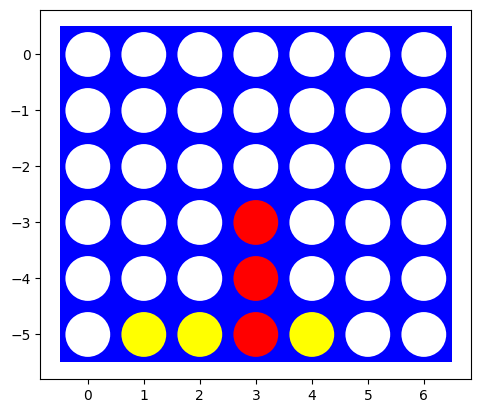

In [3]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [4]:
import numpy as np

CONNECT = 4   # số quân liên tiếp cần để thắng

def actions(board):
    """Các cột còn chỗ trống (ô trên cùng của cột bằng 0)."""
    return [c for c in range(board.shape[1]) if board[0, c] == 0]

def result(board, player, action):
    """Thả một quân của player vào cột action. Quân rơi xuống ô trống thấp nhất."""
    if board[0, action] != 0:
        raise Exception(f"Illegal action {action} by player {player}!")

    board = board.copy()
    row = np.nonzero(board[:, action] == 0)[0][-1]   # ô trống thấp nhất của cột
    board[row, action] = player
    return board

WINDOWS = {}

def get_windows(shape, k = CONNECT):
    """Chỉ số (trên board.ravel()) của mọi đoạn k ô liên tiếp theo hàng ngang, cột dọc và 2 đường chéo.
    Mỗi kích thước bàn chỉ tính một lần rồi lưu vào WINDOWS."""
    if (shape, k) not in WINDOWS:
        rows, cols = shape
        idx = np.arange(rows * cols).reshape(shape)
        w = []
        for i in range(rows):
            for j in range(cols):
                for di, dj in [(0, 1), (1, 0), (1, 1), (1, -1)]:
                    ii = [i + di * t for t in range(k)]
                    jj = [j + dj * t for t in range(k)]
                    if ii[-1] < rows and 0 <= min(jj) and max(jj) < cols:
                        w.append(idx[ii, jj])
        WINDOWS[(shape, k)] = np.array(w, dtype = int).reshape(-1, k)
    return WINDOWS[(shape, k)]

def check_board(board):
    """Trả về 1 hoặc -1 (người thắng), 'd' (hòa: bàn đầy) hoặc 'n' (chưa kết thúc)."""
    s = board.ravel()[get_windows(board.shape)].sum(axis = 1)   # tổng của từng đoạn 4 ô
    if np.any(s == CONNECT): return 1
    if np.any(s == -CONNECT): return -1
    if np.all(board[0] != 0): return 'd'
    return 'n'

def terminal(board):
    """Trò chơi đã kết thúc chưa?"""
    return check_board(board) != 'n'

def utility(board, player = 1):
    """Utility từ góc nhìn của player: +1 thắng, 0 hòa, -1 thua. None nếu chưa kết thúc."""
    goal = check_board(board)
    if goal == player: return +1
    if goal == 'd': return 0
    if goal == -player: return -1
    return None

`check_board()` không dò từng ô bằng vòng lặp. Với mỗi kích thước bàn, hàm tính sẵn một lần danh sách mọi đoạn 4 ô liên tiếp (`get_windows`).
Khi kiểm tra, nó lấy giá trị của tất cả các đoạn cùng lúc bằng numpy và cộng lại: đoạn có tổng `4` là Đỏ thắng, tổng `-4` là Vàng thắng.
Cách này nhanh hơn khoảng 4 lần so với dò từng hướng bằng cách cắt mảng, và quan trọng vì `utility()` được gọi ở **mọi** nút của cây tìm kiếm.
Bàn $6 \times 7$ có 69 đoạn 4 ô; bàn $4 \times 4$ có 10 đoạn.

Thử các hàm trên bàn chuẩn và bàn nhỏ:

actions: [0, 1, 2, 3, 4, 5, 6]
[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0 -1  0  0  0]
 [ 0  0  1  1  0  0  0]]
check_board: n | terminal: False | utility(1): None
[[ 0  0  0  0  0]
 [ 0  0  0  0  0]
 [-1 -1 -1  0  0]
 [ 1  1  1  1  0]]
check_board: 1 | utility(1): 1 | utility(-1): -1


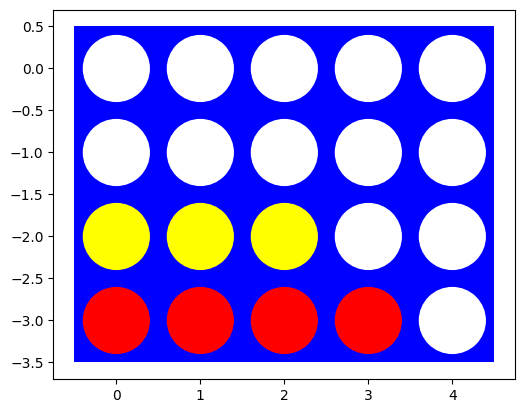

Số đoạn 4 ô: 6x7 = 69 | 4x4 = 10
Cận trên 3^42 = 1.09e+20; cận trên có trọng lực 127^7 = 5.33e+14; cây trò chơi 7^42 = 3.12e+35


In [5]:
board = empty_board()
print("actions:", actions(board))
board = result(board, 1, 3)
board = result(board, -1, 3)
board = result(board, 1, 2)
print(board)
print("check_board:", check_board(board), "| terminal:", terminal(board), "| utility(1):", utility(board, 1))

# bàn 4 x 5: Đỏ có 4 quân hàng ngang ở đáy
small = empty_board((4, 5))
for a in [0, 0, 1, 1, 2, 2, 3]:
    small = result(small, 1 if np.sum(small != 0) % 2 == 0 else -1, a)
print(small)
print("check_board:", check_board(small), "| utility(1):", utility(small, 1), "| utility(-1):", utility(small, -1))
visualize(small)

print("Số đoạn 4 ô: 6x7 =", len(get_windows((6, 7))), "| 4x4 =", len(get_windows((4, 4))))
print(f"Cận trên 3^42 = {3**42:.2e}; cận trên có trọng lực 127^7 = {127**7:.2e}; cây trò chơi 7^42 = {7**42:.2e}")

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [6]:
def random_player(board, player = 1):
    """Chọn ngẫu nhiên một cột còn chỗ (xác suất bằng nhau). player không dùng đến."""
    return np.random.choice(actions(board))

def play(red, yellow, N = 100, shape = (6, 7), show_final_board = False):
    """Cho hai agent đấu N ván trên bàn kích thước shape. red (1) đi trước.
    red và yellow là các hàm agent nhận bàn cờ (percept) và người chơi, trả về cột muốn đi."""
    results = {1: 0, -1: 0, 'd': 0}

    for i in range(N):
        board = empty_board(shape)
        player, agent = 1, red

        while True:
            a = agent(board, player)
            board = result(board, player, a)

            win = check_board(board)   # 'n' nếu ván chưa kết thúc
            if win != 'n':
                results[win] += 1
                break

            # đổi lượt
            player, agent = -player, (yellow if player == 1 else red)

        if show_final_board:
            visualize(board)

    return results

Môi trường `play()` làm giống hàm `play()` của tic-tac-toe trong `tictactoe.py`: hai agent lần lượt nhận bàn cờ và trả về nước đi.
Kết quả là số ván Đỏ thắng (`1`), Vàng thắng (`-1`) và hòa (`'d'`).

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [7]:
print("Random (Đỏ, đi trước) vs. Random (Vàng), bàn 6x7:")
%time random_results = play(random_player, random_player, N = 1000)
display(random_results)

print("Random vs. Random, bàn 4x4:")
%time display(play(random_player, random_player, N = 1000, shape = (4, 4)))

Random (Đỏ, đi trước) vs. Random (Vàng), bàn 6x7:


CPU times: user 322 ms, sys: 10.3 ms, total: 332 ms
Wall time: 333 ms


{1: 541, -1: 457, 'd': 2}

Random vs. Random, bàn 4x4:


{1: 285, -1: 239, 'd': 476}

CPU times: user 215 ms, sys: 13.7 ms, total: 229 ms
Wall time: 217 ms


**Nhận xét:** * Bàn 6×7: Đỏ (đi trước) thắng **541/1000** ván (54,1%), Vàng thắng **457** (45,7%), chỉ **2** ván hòa.
  Kết quả này hợp lý: người đi trước luôn có số quân bằng hoặc hơn đối thủ 1 quân, nên dễ tạo hàng 4 trước.
  Connect 4 cũng đã được giải: với lối chơi tối ưu, người đi trước thắng. Hòa rất hiếm vì hai Random gần như luôn vô tình tạo ra một hàng 4 trước khi bàn đầy.
* Bàn 4×4: hòa tới **476/1000** ván. Bàn nhỏ chỉ có 10 đoạn 4 ô, nên bàn thường đầy trước khi có ai nối được 4. Đỏ vẫn thắng nhiều hơn Vàng (285 so với 239).
* Một ván Random rất nhanh: 1000 ván trên bàn 6×7 mất khoảng 0,33 giây.

## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [8]:
import math
import time

# global variables
DEBUG = 1          # 1 ... in số nút đã duyệt, 2 ... in từng nút
COUNT = 0
TIME_LIMIT = None  # giới hạn thời gian (giây) chỉ dùng cho thí nghiệm đo thời gian; None = không giới hạn
DEADLINE = None

def alpha_beta_search(board, player = 1, order = None):
    """Minimax search với alpha-beta pruning, tìm tới trạng thái kết thúc.
    order: hàm order(board, player) trả về danh sách nước đi theo thứ tự muốn thử; None = actions(board)."""
    global DEBUG, COUNT, DEADLINE
    COUNT = 0
    DEADLINE = None if TIME_LIMIT is None else time.perf_counter() + TIME_LIMIT

    value, move = max_value_ab(board, player, -math.inf, +math.inf, order)

    if DEBUG >= 1: print(f"Number of nodes searched: {COUNT}")

    return {"move": move, "value": value}

def max_value_ab(state, player, alpha, beta, order):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
    if DEADLINE is not None and time.perf_counter() > DEADLINE:
        raise TimeoutError(f"stopped after {TIME_LIMIT} s")

    # return utility of state if it is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print(f"max: {state.tolist()} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: return v, None

    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in (actions(state) if order is None else order(state, player)):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta, order)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta: return v, move

    return v, move

def min_value_ab(state, player, alpha, beta, order):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    if DEADLINE is not None and time.perf_counter() > DEADLINE:
        raise TimeoutError(f"stopped after {TIME_LIMIT} s")

    # return utility of state if it is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print(f"min: {state.tolist()} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: return v, None

    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in (actions(state) if order is None else order(state, -player)):
        v2, a2 = max_value_ab(result(state, -player, a), player, alpha, beta, order)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: return v, move

    return v, move

Cài đặt theo đúng khung `alpha_beta_search` / `max_value_ab` / `min_value_ab` của notebook tic-tac-toe. Có 3 điểm khác:

* Người chơi là `1` / `-1`, nên đối thủ của `player` là `-player`.
* Tham số `order` cho phép đổi thứ tự thử nước đi (dùng ở phần Move ordering).
* `TIME_LIMIT` chỉ dùng trong thí nghiệm đo thời gian, để dừng các lần tìm kiếm quá lâu thay vì chạy hàng giờ.

Agent được viết thành **class** để lưu thông tin trạng thái giữa các lần gọi, theo [store_agent_state_information.ipynb](store_agent_state_information.ipynb). Class lưu:

* cấu hình tìm kiếm (hàm tìm kiếm và tham số);
* `memory`: nước đi đã tính cho từng cặp (bàn cờ, người chơi). Thuật toán tất định nên gặp lại bàn cũ thì dùng lại kết quả, không tìm lại;
* thống kê số nước đã đi và tổng thời gian suy nghĩ, để tính **thời gian trung bình mỗi nước đi**.

Hàm agent là `agent.act(board, player = 1)`, cùng dạng với `random_player`.

In [9]:
class SearchAgent:
    """Agent dùng một hàm tìm kiếm. Thông tin trạng thái được lưu trong đối tượng."""

    def __init__(self, search, name = "agent", use_memory = True, **search_args):
        self.search = search              # hàm tìm kiếm, ví dụ alpha_beta_search
        self.search_args = search_args    # tham số thêm cho hàm tìm kiếm (order, cutoff, N, ...)
        self.name = name
        self.use_memory = use_memory      # chỉ dùng memory cho thuật toán tất định
        self.memory = {}                  # (bàn cờ, người chơi) -> nước đi đã tính
        self.moves = 0                    # số nước đã đi
        self.total_time = 0.0             # tổng thời gian suy nghĩ (giây)

    def act(self, board, player = 1):
        start = time.perf_counter()
        key = (board.tobytes(), board.shape, player)
        if self.use_memory and key in self.memory:
            move = self.memory[key]
        else:
            res = self.search(board, player = player, **self.search_args)
            move = res["move"] if isinstance(res, dict) else res
            if self.use_memory: self.memory[key] = move
        self.moves += 1
        self.total_time += time.perf_counter() - start
        return move

    def avg_time(self):
        """Thời gian trung bình mỗi nước đi (giây)."""
        return self.total_time / max(self.moves, 1)

    def reset_stats(self):
        self.moves, self.total_time = 0, 0.0

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

B1 thắng ngay (ngang) - nước đi mong đợi: 3


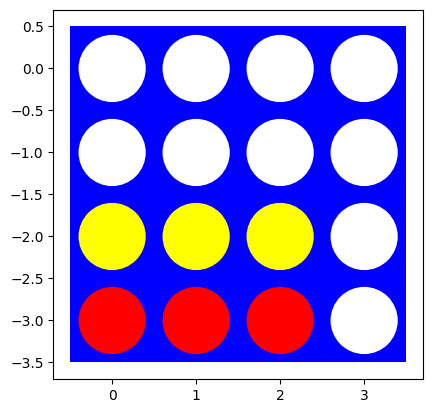

Number of nodes searched: 2670


{'move': 3, 'value': 1}

CPU times: user 24.1 ms, sys: 265 μs, total: 24.4 ms
Wall time: 24.4 ms

B2 thắng ngay (dọc) - nước đi mong đợi: 0


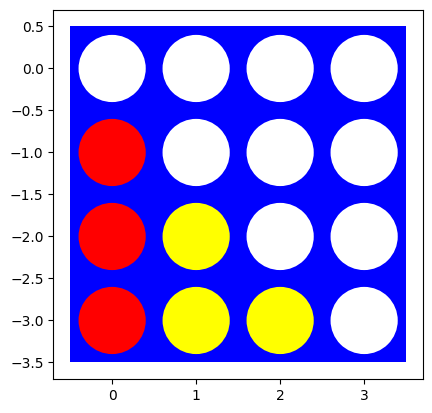

Number of nodes searched: 162


{'move': 0, 'value': 1}

CPU times: user 1.94 ms, sys: 91 μs, total: 2.03 ms
Wall time: 2.03 ms

B3 phải chặn (dọc) - nước đi mong đợi: 0


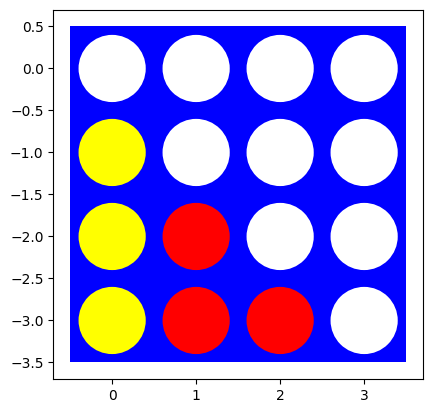

Number of nodes searched: 128


{'move': 0, 'value': 0}

CPU times: user 1.65 ms, sys: 95 μs, total: 1.74 ms
Wall time: 1.73 ms

B4 phải chặn (ngang) - nước đi mong đợi: 3


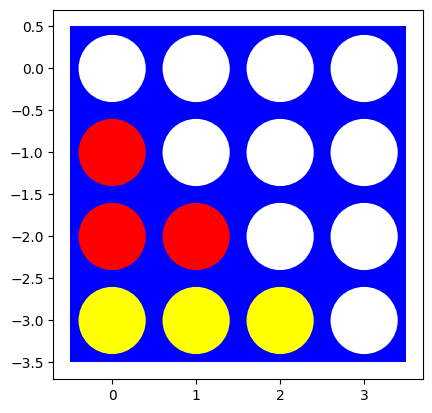

Number of nodes searched: 2862


{'move': 3, 'value': 0}

CPU times: user 26.5 ms, sys: 316 μs, total: 26.9 ms
Wall time: 26.8 ms

B5 thế ép (zugzwang) - nước đi mong đợi: 2


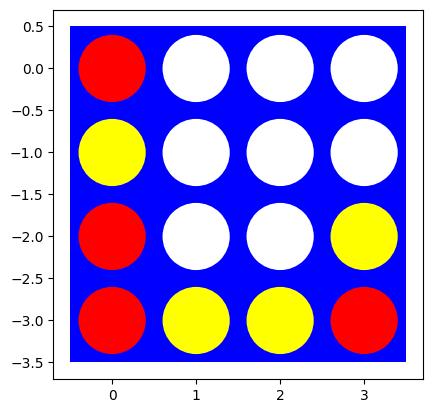

Number of nodes searched: 251


{'move': 2, 'value': 1}

CPU times: user 2.76 ms, sys: 115 μs, total: 2.88 ms
Wall time: 2.9 ms

B6 bàn rỗng - nước đi mong đợi: None


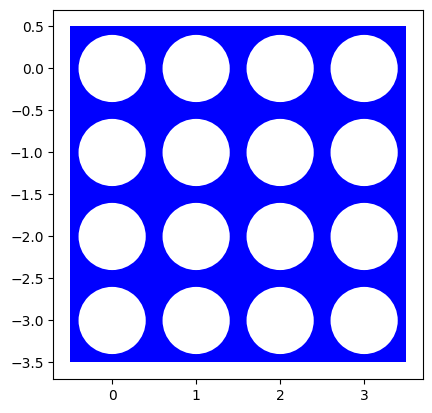

Number of nodes searched: 62889


{'move': 0, 'value': 0}

CPU times: user 554 ms, sys: 2.09 ms, total: 556 ms
Wall time: 556 ms



In [10]:
def make_board(pattern, shape = (4, 4)):
    """Đặt mẫu (liệt kê các hàng từ trên xuống) vào góc dưới bên trái của bàn rỗng kích thước shape."""
    board = empty_board(shape)
    pattern = np.array(pattern)
    board[shape[0] - pattern.shape[0]:, :pattern.shape[1]] = pattern
    return board

# Các bàn kiểm thử. Đỏ (1) luôn là người đi tiếp. Ghi chú: nước đi mong đợi.
TEST_BOARDS = {
    "B1 thắng ngay (ngang)": ([[ 0,  0,  0, 0],
                               [ 0,  0,  0, 0],
                               [-1, -1, -1, 0],
                               [ 1,  1,  1, 0]], 3),
    "B2 thắng ngay (dọc)":   ([[ 0,  0,  0, 0],
                               [ 1,  0,  0, 0],
                               [ 1, -1,  0, 0],
                               [ 1, -1, -1, 0]], 0),
    "B3 phải chặn (dọc)":    ([[ 0,  0,  0, 0],
                               [-1,  0,  0, 0],
                               [-1,  1,  0, 0],
                               [-1,  1,  1, 0]], 0),
    "B4 phải chặn (ngang)":  ([[ 0,  0,  0, 0],
                               [ 1,  0,  0, 0],
                               [ 1,  1,  0, 0],
                               [-1, -1, -1, 0]], 3),
    "B5 thế ép (zugzwang)":            ([[ 1,  0,  0,  0],
                               [-1,  0,  0,  0],
                               [ 1,  0,  0, -1],
                               [ 1, -1, -1,  1]], 2),
    "B6 bàn rỗng":           ([[0, 0, 0, 0]], None),
}

DEBUG = 1
for name, (pattern, expected) in TEST_BOARDS.items():
    board = make_board(pattern, (4, 4))
    print(f"{name} - nước đi mong đợi: {expected}")
    visualize(board)
    %time display(alpha_beta_search(board, player = 1))
    print()

Ý nghĩa của từng bàn kiểm thử (cột đánh số 0–3 từ trái sang):

* **B1, B2:** Đỏ có 3 quân liên tiếp và thắng ngay nếu đi đúng cột (cột 3, cột 0).
* **B3, B4:** Vàng có 3 quân liên tiếp; Đỏ phải chặn ở cột 0 (B3) hoặc cột 3 (B4), nếu không sẽ thua ở nước sau.
* **B5 (thế ép – zugzwang):** không có nước thắng ngay. Đỏ đi cột 2 (ô hàng 2, cột 2) để có 3 quân trên đường chéo
  (0,0)–(1,1)–(2,2)–(3,3); chỉ còn thiếu ô (1,1). Ô ngay dưới nó, (2,1), trở thành ô "cấm":
  nếu Vàng đi vào (2,1), Đỏ đặt quân lên (1,1) và thắng. Trên bàn 4×4 chỉ còn ít ô trống,
  nên sớm hay muộn Vàng cũng hết nước khác và buộc phải đi vào ô cấm. Đây là thế thắng mà phải nhìn sâu mới thấy.
* **B6:** bàn rỗng, dùng để xem trường hợp xấu nhất.

**Nhận xét:** * Agent chọn **đúng nước mong đợi ở cả 6 bàn**. Giá trị Minimax cũng hợp lý:
  B1, B2, B5 có giá trị `1` (Đỏ chắc thắng); B3, B4 có giá trị `0` (chặn xong thì ván hòa).
* B5 (thế ép) có giá trị `1` chỉ sau 251 nút: tìm kiếm đầy đủ nhìn ra được thế thắng cần nhiều nước, điều mà nhìn bàn cờ không thấy ngay.
* B1 tốn 2.670 nút, còn B2 chỉ 162 nút. Lý do: ở B1 nước thắng nằm ở cột 3, là cột được thử **cuối cùng** theo thứ tự mặc định.
  Thuật toán phải duyệt hết các cây con của cột 0, 1, 2 trước. Đây là lý do cần move ordering (bên dưới).
* Ở bàn rỗng 4×4 (B6), giá trị là `0`: chơi tối ưu thì hòa. Mọi nước đều có giá trị 0, nên agent giữ nước đầu tiên tìm được là cột 0, không phải cột giữa.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

In [11]:
DEBUG = 0

def timed_search(board, player = 1, limit = None, **args):
    """Chạy alpha_beta_search, trả về (kết quả, số nút, thời gian). Kết quả None nếu vượt quá limit giây."""
    global TIME_LIMIT
    TIME_LIMIT = limit
    start = time.perf_counter()
    try:
        res = alpha_beta_search(board, player = player, **args)
    except TimeoutError:
        res = None
    TIME_LIMIT = None
    return res, COUNT, time.perf_counter() - start

print("Nước đi đầu tiên trên bàn rỗng, tăng dần kích thước (giới hạn 60 giây cho mỗi bàn):\n")
print(f"{'Bàn':>6} | {'Nước đi':>7} | {'Giá trị':>7} | {'Số nút':>12} | {'Thời gian (s)':>13} | {'Nút/giây':>9}")
for shape, limit in [((4, 4), None), ((4, 5), None), ((5, 4), 60), ((5, 5), 60), ((6, 7), 60)]:
    res, nodes, t = timed_search(empty_board(shape), limit = limit)
    move  = res["move"]  if res else "-"
    value = res["value"] if res else "chưa xong"
    print(f"{shape[0]}x{shape[1]:<4} | {move:>7} | {value:>7} | {nodes:>12,} | {t:>13.2f} | {nodes / t:>9,.0f}")

Nước đi đầu tiên trên bàn rỗng, tăng dần kích thước (giới hạn 60 giây cho mỗi bàn):

   Bàn | Nước đi | Giá trị |       Số nút | Thời gian (s) |  Nút/giây


4x4    |       0 |       0 |       62,889 |          0.55 |   113,783


4x5    |       1 |       0 |   18,026,614 |        198.48 |    90,824


5x4    |       0 |       0 |    1,227,610 |         15.66 |    78,401


5x5    |       - | chưa xong |    5,491,472 |         60.00 |    91,524


6x7    |       - | chưa xong |    5,181,034 |         60.00 |    86,350


**Nhận xét:** * Bàn 4×4: 62.889 nút, **0,55 giây**.
* **Thêm 1 cột** (4×5): 18.026.614 nút, **198 giây**, gấp khoảng 290 lần số nút.
* **Thêm 1 hàng** (5×4): 1.227.610 nút, **15,7 giây**, gấp khoảng 20 lần.
* 4×5 và 5×4 cùng có 20 ô, nhưng 4×5 tốn số nút **gấp khoảng 15 lần**. Thêm cột làm tăng hệ số rẽ nhánh (số nước đi mỗi lượt), tác động mạnh hơn nhiều so với chỉ làm ván dài hơn.
* 5×5 và 6×7: sau 60 giây vẫn chưa xong (đã duyệt khoảng 5,5 và 5,2 triệu nút).
* Tốc độ cài đặt khoảng 80.000–115.000 nút/giây và gần như không đổi. Thời gian tăng chỉ do số nút tăng.

Trên bàn $6 \times 7$ không thể tìm từ bàn rỗng. Để thấy thời gian tăng nhanh thế nào, ta đo trên bàn $6 \times 7$ **đã chơi dở**:
cho hai Random đi ngẫu nhiên tới khi chỉ còn $k$ ô trống (và ván chưa kết thúc), rồi chạy tìm kiếm đầy đủ.
Mỗi giá trị $k$ thử 3 bàn khác nhau, mỗi lần tìm giới hạn 30 giây.

In [12]:
def random_board(shape, empties):
    """Cho hai random_player đi tới khi còn đúng `empties` ô trống mà ván chưa kết thúc.
    Trả về (bàn cờ, người đi tiếp)."""
    while True:
        board, player = empty_board(shape), 1
        for i in range(shape[0] * shape[1] - empties):
            board = result(board, player, random_player(board, player))
            player = -player
            if terminal(board): break
        if not terminal(board):
            return board, player

print(f"{'Ô trống k':>9} | {'Số nút (TB 3 bàn)':>18} | {'Lớn nhất':>10} | {'Thời gian TB (s)':>16} | {'Xong/3':>6}")
growth = []
for k in [8, 10, 12, 14, 16, 18]:
    nodes_k, time_k, done = [], [], 0
    for rep in range(3):
        board, player = random_board((6, 7), k)
        res, nodes, t = timed_search(board, player, limit = 30)
        nodes_k.append(nodes); time_k.append(t); done += res is not None
    growth.append((k, np.mean(nodes_k), np.mean(time_k)))
    print(f"{k:>9} | {np.mean(nodes_k):>18,.0f} | {max(nodes_k):>10,} | {np.mean(time_k):>16.3f} | {done:>6}")

# ngoại suy: số nút tăng theo hàm mũ của số ô trống -> khớp đường thẳng log10(số nút) theo k
ks = np.array([g[0] for g in growth]); ns = np.array([g[1] for g in growth]); ts = np.array([g[2] for g in growth])
slope, intercept = np.polyfit(ks, np.log10(ns), 1)
rate = ns.sum() / ts.sum()
nodes_42 = 10 ** (slope * 42 + intercept)
print(f"\nMỗi ô trống thêm vào làm số nút tăng khoảng {10 ** slope:.2f} lần.")
print(f"Tốc độ đo được: khoảng {rate:,.0f} nút/giây.")
print(f"Ngoại suy cho bàn rỗng 6x7 (42 ô trống): khoảng {nodes_42:.1e} nút, "
      f"tức khoảng {nodes_42 / rate / 3600 / 24 / 365:.1e} năm.")

Ô trống k |  Số nút (TB 3 bàn) |   Lớn nhất | Thời gian TB (s) | Xong/3
        8 |                 89 |        204 |            0.002 |      3
       10 |                682 |      1,959 |            0.012 |      3


       12 |              1,268 |      3,603 |            0.023 |      3


       14 |              6,829 |     19,058 |            0.122 |      3


       16 |            204,367 |    604,690 |            2.175 |      3


       18 |          1,225,095 |  3,149,427 |           11.702 |      2

Mỗi ô trống thêm vào làm số nút tăng khoảng 2.58 lần.
Tốc độ đo được: khoảng 102,487 nút/giây.
Ngoại suy cho bàn rỗng 6x7 (42 ô trống): khoảng 6.4e+15 nút, tức khoảng 2.0e+03 năm.


**Nhận xét:** Số nút trung bình tăng từ 89 (8 ô trống) lên 1.225.095 (18 ô trống). Ở 18 ô trống có 1/3 bàn bị dừng sau 30 giây, nên con số thật còn lớn hơn.
Kết quả dao động khá nhiều giữa các bàn: bàn đã gần phân thắng thua thì cắt tỉa được nhiều. Ví dụ ở lần chạy này, 12 ô trống chỉ tốn 1.268 nút trung bình, còn 16 ô trống tốn 204.367.
Khớp một đường thẳng theo thang log cho thấy **mỗi ô trống thêm vào làm số nút tăng khoảng 2,58 lần**.
Ngoại suy tới bàn rỗng (42 ô trống) được khoảng $6.4 \times 10^{15}$ nút, tức khoảng **2.000 năm** ở tốc độ đo được (khoảng 102.000 nút/giây).

**Vì sao Minimax đầy đủ không khả thi trên bàn chuẩn $6 \times 7$:** Thời gian tăng theo hàm mũ của số ô trống, và bàn 6×7 có tới 42 ô.

* **Từ đo đạc:** 5×5 (25 ô) đã không xong trong 60 giây. Ngoại suy từ các bàn chơi dở cho thấy bàn rỗng 6×7 cần khoảng 2.000 năm.
  Con số này còn là ước lượng **thấp**: các bàn chơi dở có ít cột còn trống, và lần đo dừng ở 30 giây bị tính thiếu số nút.
* **Từ lý thuyết:** cây trò chơi có khoảng $10^{21}$ nút (cận trên $7^{42} \approx 3 \times 10^{35}$).
  Ngay cả trường hợp tốt nhất của Alpha-Beta (thứ tự nước đi hoàn hảo, khoảng $b^{d/2}$ nút) vẫn là $7^{21} \approx 5.6 \times 10^{17}$ nút.
  Ở tốc độ khoảng $10^5$ nút/giây, như vậy mất khoảng 180.000 năm.
* Các chương trình đã giải được Connect 4 phải dùng bitboard, bảng chuyển vị và sách khai cuộc viết bằng C/C++.
  Với notebook Python, cách khả thi là **cắt độ sâu + heuristic** (Task 4) hoặc **Monte Carlo** (Task 5).

### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

Hai chiến lược sắp thứ tự nước đi được so sánh với thứ tự mặc định (cột 0 → cột $c-1$):

1. **center:** thử các cột gần giữa trước. Quân ở giữa nằm trong nhiều đoạn 4 ô nhất, nên thường là nước tốt hơn
   (giống `priority` ưu tiên ô giữa trong notebook tic-tac-toe).
2. **threat:** thử trước các nước **thắng ngay**, rồi các nước **chặn** nước thắng ngay của đối thủ, rồi các cột còn lại theo thứ tự center.
   Cách này tốn thêm một lần `check_board` cho mỗi nước đi, nhưng tìm ra nước quyết định sớm hơn nên cắt tỉa được nhiều hơn.

In [13]:
def center_order(board, player):
    """Thử các cột gần giữa trước."""
    c = (board.shape[1] - 1) / 2
    return sorted(actions(board), key = lambda a: abs(a - c))

def threat_order(board, player):
    """Thắng ngay trước, rồi chặn nước thắng ngay của đối thủ, rồi theo thứ tự center."""
    acts = center_order(board, player)
    win   = [a for a in acts if check_board(result(board, player, a)) == player]
    block = [a for a in acts if a not in win and check_board(result(board, -player, a)) == -player]
    rest  = [a for a in acts if a not in win and a not in block]
    return win + block + rest

board = make_board(TEST_BOARDS["B4 phải chặn (ngang)"][0], (4, 4))
print("B4 - mặc định:", actions(board), "| center:", center_order(board, 1), "| threat:", threat_order(board, 1))

B4 - mặc định: [0, 1, 2, 3] | center: [1, 2, 0, 3] | threat: [3, 1, 2, 0]


In [14]:
DEBUG = 0
ORDERS = {"none": None, "center": center_order, "threat": threat_order}

# bàn kiểm thử 4x4 và 5 bàn 6x7 chơi dở còn 16 ô trống (dùng chung cho cả 3 chiến lược)
boards = [(name, make_board(p, (4, 4)), 1) for name, (p, e) in TEST_BOARDS.items()]
boards += [(f"6x7 ngẫu nhiên #{i + 1} (16 ô trống)", *random_board((6, 7), 16)) for i in range(5)]

print(f"{'Bàn':<32} | " + " | ".join(f"{o + ': nút':>14} {'(s)':>7}" for o in ORDERS))
total = {o: [0, 0.0] for o in ORDERS}
for name, board, player in boards:
    row = []
    for o, f in ORDERS.items():
        res, nodes, t = timed_search(board, player, limit = 60, order = f)
        total[o][0] += nodes; total[o][1] += t
        row.append(f"{nodes:>14,} {t:>7.3f}")
    print(f"{name:<32} | " + " | ".join(row))
print(f"{'TỔNG':<32} | " + " | ".join(f"{total[o][0]:>14,} {total[o][1]:>7.2f}" for o in ORDERS))

Bàn                              |      none: nút     (s) |    center: nút     (s) |    threat: nút     (s)
B1 thắng ngay (ngang)            |          2,670   0.025 |          2,988   0.029 |            134   0.005
B2 thắng ngay (dọc)              |            162   0.002 |            479   0.005 |            167   0.006
B3 phải chặn (dọc)               |            128   0.001 |            591   0.006 |            118   0.004
B4 phải chặn (ngang)             |          2,862   0.028 |          2,766   0.027 |            447   0.016
B5 thế ép (zugzwang)             |            251   0.002 |            251   0.002 |            226   0.007


B6 bàn rỗng                      |         62,889   0.583 |        155,968   1.472 |         67,921   2.211


6x7 ngẫu nhiên #1 (16 ô trống)   |        121,024   1.171 |         82,956   0.828 |         35,335   1.264
6x7 ngẫu nhiên #2 (16 ô trống)   |          4,456   0.039 |            285   0.003 |             85   0.006
6x7 ngẫu nhiên #3 (16 ô trống)   |          2,997   0.028 |            160   0.001 |             12   0.001


6x7 ngẫu nhiên #4 (16 ô trống)   |         40,764   0.393 |         15,974   0.155 |          3,931   0.161
6x7 ngẫu nhiên #5 (16 ô trống)   |          1,628   0.015 |             62   0.001 |             21   0.001
TỔNG                             |        239,831    2.29 |        262,480    2.53 |        108,397    3.68


**Nhận xét:** * **Tổng cộng 11 bàn:** none 239.831 nút (2,29 s), center 262.480 nút (2,53 s), **threat 108.397 nút** (3,68 s).
  Threat giảm số nút khoảng 2,2 lần so với thứ tự mặc định.
* **Threat có tác dụng mạnh nhất ở những bàn đã có nước quyết định:** B1 giảm từ 2.670 xuống 134 nút, B4 từ 2.862 xuống 447.
  Bàn 6×7 ngẫu nhiên #4 giảm từ 40.764 xuống 3.931, bàn #1 từ 121.024 xuống 35.335.
  Khi nước thắng (hoặc nước chặn) được thử đầu tiên, `alpha`/`beta` sớm đạt giá trị tốt nhất, nên các nhánh sau bị cắt ngay.
* **Center giúp ở bàn 6×7** (ví dụ #2 giảm từ 4.456 xuống 285 nút), nhưng **làm tệ hơn ở bàn 4×4 rỗng** (155.968 so với 62.889 nút).
  Bàn 4×4 rỗng là thế hòa: không có nước nào "tốt hơn" để cắt tỉa sớm, và với 4 cột thì khái niệm cột giữa ít ý nghĩa.
* **Ít nút hơn chưa chắc nhanh hơn:** threat tốn thêm `check_board` cho mỗi nước ở mỗi nút. Ở bàn 4×4 rỗng nó chậm nhất (2,21 s), dù số nút gần bằng none.
  Tổng thời gian của threat ở đây cao nhất vì phần lớn bàn có cây nhỏ, chi phí phụ lấn át phần cắt tỉa được.
  Ở các cây lớn (bàn #1, #4) số nút giảm mạnh, nên thời gian ngang bằng hoặc nhanh hơn.
* Kết luận: thứ tự nước đi tốt đưa Alpha-Beta về gần trường hợp tốt nhất $b^{d/2}$. Hiệu quả phụ thuộc vào việc bàn cờ có nước quyết định hay không.

### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [15]:
DEBUG = 1
board = empty_board((4, 4))
print("Nước đi đầu tiên trên bàn 4x4 rỗng:")
%time display(alpha_beta_search(board, player = 1))

Nước đi đầu tiên trên bàn 4x4 rỗng:


Number of nodes searched: 62889


{'move': 0, 'value': 0}

CPU times: user 554 ms, sys: 1.07 ms, total: 555 ms
Wall time: 555 ms


In [16]:
DEBUG = 0
# Xem thời gian bị tiêu ở đâu (xem HOWTO: Profiling Python Code). In 8 hàm tốn thời gian nhất.
import cProfile, pstats
profiler = cProfile.Profile()
profiler.enable()
alpha_beta_search(empty_board((4, 4)), player = 1)
profiler.disable()
pstats.Stats(profiler).sort_stats("tottime").print_stats(8)

         1899803 function calls (1836913 primitive calls) in 1.013 seconds

   Ordered by: internal time
   List reduced from 125 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
    62889    0.219    0.000    0.637    0.000 /var/folders/2v/c85skmb11x7g_qx9bndy9n200000gn/T/ipykernel_4376/2201082072.py:38(check_board)
   234666    0.179    0.000    0.179    0.000 {method 'reduce' of 'numpy.ufunc' objects}
    62889    0.105    0.000    0.743    0.000 /var/folders/2v/c85skmb11x7g_qx9bndy9n200000gn/T/ipykernel_4376/2201082072.py:50(utility)
   171777    0.102    0.000    0.241    0.000 /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:86(_wrapreduction_any_all)
    62888    0.096    0.000    0.174    0.000 /var/folders/2v/c85skmb11x7g_qx9bndy9n200000gn/T/ipykernel_4376/2201082072.py:9(result)
   119735    0.042    0.000    0.211    0.000 /Library/Frameworks/Python.framework/Version

In [17]:
# Cải tiến 1: agent lưu nước đi đã tính trong memory (class SearchAgent).
# Lần đầu phải tìm kiếm đầy đủ, các lần sau gặp lại bàn rỗng thì trả lời ngay.
DEBUG = 0
ab_agent = SearchAgent(alpha_beta_search, name = "alpha-beta")
board = empty_board((4, 4))
%time print("Lần 1:", ab_agent.act(board, 1))
%time print("Lần 2:", ab_agent.act(board, 1))

Lần 1: 0
CPU times: user 560 ms, sys: 997 μs, total: 561 ms
Wall time: 561 ms
Lần 2: 0
CPU times: user 17 μs, sys: 0 ns, total: 17 μs
Wall time: 19.1 μs


**Nhận xét:** * Nước đầu tiên trên bàn 4×4 rỗng tốn **62.889 nút, khoảng 0,56 giây** (trên bàn 6×7 thì không làm được, xem phần trên).
* Profile (chạy chậm hơn do bản thân profiler) cho thấy `utility` / `check_board` chiếm khoảng **0,74 / 1,01 giây**, tức gần 3/4 thời gian.
  `result()` (sao chép bàn cờ) chiếm khoảng 0,17 giây. Muốn nhanh hơn thì phải làm cho bước kiểm tra kết thúc nhanh hơn.
* Agent có memory: lần 1 mất 561 ms, **lần 2 chỉ mất 19 µs** vì lấy lại nước đã tính.

Những cách agent có thể dùng để giảm thời gian nước đi đầu tiên:

* **Lưu kết quả (memory / opening book):** bàn rỗng luôn giống nhau, nên chỉ cần tính một lần rồi lưu lại
  (đã cài trong `SearchAgent` ở trên: lần 2 gần như tức thì). Có thể tính trước cả "sách khai cuộc" cho vài nước đầu.
* **Bảng chuyển vị (transposition table):** lưu giá trị của các trạng thái đã duyệt *trong lúc tìm kiếm*,
  vì cùng một trạng thái xuất hiện qua nhiều thứ tự nước đi. Việc này biến cây thành đồ thị và giảm số nút rất nhiều.
* **Đối xứng:** bàn cờ đối xứng trái–phải, nên trạng thái và ảnh gương của nó có cùng giá trị; ở bàn rỗng chỉ cần xét nửa số cột.
* **Move ordering** tốt hơn (phần trên), và **cắt độ sâu + heuristic** (Task 4) khi chấp nhận nước đi gần tối ưu.
* **Tăng tốc cài đặt:** profile cho thấy phần lớn thời gian nằm ở `check_board` / `utility` và `result` (tạo bản sao numpy).
  Dùng bitboard (mỗi bên là một số nguyên 64 bit) sẽ nhanh hơn hàng chục lần.

### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

In [18]:
DEBUG = 0
ab_agent = SearchAgent(alpha_beta_search, name = "Alpha-Beta (4x4)", order = threat_order)

# bảng tổng hợp ở cuối notebook: (số ván, thắng, hòa, thua, thời gian TB mỗi nước)
SUMMARY = {("Random (6x7)", "đi trước"): (1000, random_results[1], random_results['d'], random_results[-1], None)}

print("alpha-beta (Đỏ, đi trước) vs. random, bàn 4x4:")
ab_agent.reset_stats()
%time res = play(ab_agent.act, random_player, N = 100, shape = (4, 4))
display(res)
SUMMARY[(ab_agent.name, "đi trước")] = (100, res[1], res['d'], res[-1], ab_agent.avg_time())
print(f"Thời gian TB mỗi nước của alpha-beta: {ab_agent.avg_time() * 1000:.1f} ms ({ab_agent.moves} nước)")

print()
print("random (Đỏ, đi trước) vs. alpha-beta, bàn 4x4:")
ab_agent.reset_stats()
%time res = play(random_player, ab_agent.act, N = 100, shape = (4, 4))
display(res)
SUMMARY[(ab_agent.name, "đi sau")] = (100, res[-1], res['d'], res[1], ab_agent.avg_time())
print(f"Thời gian TB mỗi nước của alpha-beta: {ab_agent.avg_time() * 1000:.1f} ms ({ab_agent.moves} nước)")
print(f"Số bàn đã lưu trong memory: {len(ab_agent.memory)}")

alpha-beta (Đỏ, đi trước) vs. random, bàn 4x4:


CPU times: user 7.53 s, sys: 13.2 ms, total: 7.55 s
Wall time: 7.55 s


{1: 52, -1: 0, 'd': 48}

Thời gian TB mỗi nước của alpha-beta: 10.5 ms (717 nước)

random (Đỏ, đi trước) vs. alpha-beta, bàn 4x4:


CPU times: user 9.95 s, sys: 11.6 ms, total: 9.96 s
Wall time: 9.96 s


{1: 0, -1: 79, 'd': 21}

Thời gian TB mỗi nước của alpha-beta: 14.6 ms (680 nước)
Số bàn đã lưu trong memory: 647


**Nhận xét:** * **Alpha-Beta không thua ván nào** trong 200 ván.
  * Đi trước: thắng 52, hòa 48.
  * Đi sau: thắng 79, hòa 21.
* Bàn 4×4 là thế hòa khi chơi tối ưu, nên agent không thể tự ép thắng. Mọi ván thắng đều do Random đi sai.
* Agent chọn nước **đầu tiên** trong các nước cùng giá trị. Ví dụ ở bàn rỗng nó chọn cột 0, không chọn nước làm khó đối thủ nhất, vì Minimax giả định đối thủ chơi tối ưu.
  Đó có thể là lý do agent đi trước thắng ít hơn đi sau: nước mở đầu cột 0 an toàn nhưng không gây sức ép.
  Một quy tắc phá hòa tốt hơn, ví dụ ưu tiên cột giữa, sẽ tận dụng lỗi của Random tốt hơn.
* Thời gian trung bình **10,5 ms/nước** (đi trước) và **14,6 ms/nước** (đi sau).
  Memory lưu 647 bàn. Nhờ vậy nước đầu (0,56 giây) chỉ phải tính 1 lần cho cả 100 ván, và mỗi loạt 100 ván chỉ mất 7,6 giây và 10 giây.

## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

In [19]:
def eval_fun(board, player = 1):
    """Hàm đánh giá heuristic. Trả về (giá trị, terminal?).
    1. Trạng thái kết thúc: trả về utility (+1, 0, -1).
    2. Trạng thái chưa kết thúc: tổng có trọng số của các đặc trưng, rồi nén vào khoảng (-1, 1).
       Đặc trưng xét trên mọi đoạn CONNECT ô liên tiếp (ngang, dọc, chéo):
       * đoạn có CONNECT-1 quân của mình, phần còn lại trống: +5 (sắp thắng)
       * đoạn có CONNECT-2 quân của mình, phần còn lại trống: +2
       * tương tự cho đối thủ với dấu trừ
       * mỗi quân ở cột giữa: +3 cho mình, -3 cho đối thủ
       Điểm thô x được chia cho 50 rồi nén bằng x / (1 + |x|), nên giá trị luôn nằm trong (-1, 1),
       nhỏ hơn hẳn utility của một ván thắng (+1) hoặc thua (-1)."""
    u = utility(board, player)
    if u is not None: return u, True

    w = board.ravel()[get_windows(board.shape)]
    mine   = np.sum(w == player, axis = 1)
    theirs = np.sum(w == -player, axis = 1)

    score  = 5 * np.sum((mine == CONNECT - 1) & (theirs == 0)) + 2 * np.sum((mine == CONNECT - 2) & (theirs == 0))
    score -= 5 * np.sum((theirs == CONNECT - 1) & (mine == 0)) + 2 * np.sum((theirs == CONNECT - 2) & (mine == 0))

    center = board[:, board.shape[1] // 2]
    score += 3 * (np.sum(center == player) - np.sum(center == -player))

    x = score / 50
    return x / (1 + abs(x)), False

for name, (pattern, expected) in list(TEST_BOARDS.items())[:5]:
    board = make_board(pattern, (6, 7))
    print(f"{name}: eval cho Đỏ = {eval_fun(board, 1)}, eval cho Vàng = {eval_fun(board, -1)}")

# kiểm tra khoảng giá trị trên 2000 bàn ngẫu nhiên chưa kết thúc
vals = [eval_fun(random_board((6, 7), np.random.randint(5, 40))[0], 1)[0] for i in range(2000)]
print(f"\nTrên 2000 bàn ngẫu nhiên chưa kết thúc: min = {min(vals):.3f}, max = {max(vals):.3f}")

B1 thắng ngay (ngang): eval cho Đỏ = (np.float64(0.0), False), eval cho Vàng = (np.float64(0.0), False)
B2 thắng ngay (dọc): eval cho Đỏ = (np.float64(0.056603773584905655), False), eval cho Vàng = (np.float64(-0.056603773584905655), False)
B3 phải chặn (dọc): eval cho Đỏ = (np.float64(-0.056603773584905655), False), eval cho Vàng = (np.float64(0.056603773584905655), False)
B4 phải chặn (ngang): eval cho Đỏ = (np.float64(-0.056603773584905655), False), eval cho Vàng = (np.float64(0.056603773584905655), False)
B5 thế ép (zugzwang): eval cho Đỏ = (np.float64(0.0), False), eval cho Vàng = (np.float64(0.0), False)



Trên 2000 bàn ngẫu nhiên chưa kết thúc: min = -0.468, max = 0.537


**Nhận xét:** * Hàm đánh giá có tính đối xứng: giá trị cho Đỏ luôn bằng âm giá trị cho Vàng (ví dụ B2: +0,057 và −0,057), đúng với trò chơi tổng bằng 0.
* Trên 2000 bàn ngẫu nhiên, giá trị nằm trong **[−0,468; 0,537]**, luôn trong khoảng (−1, 1).
  Vì vậy thắng/thua thật (±1) luôn được ưu tiên hơn mọi đánh giá heuristic.
* Điểm yếu: hàm đánh giá **không biết ai đi tiếp**. Ở B1 cả hai bên đều có 3 quân với ô thứ 4 trống, nên giá trị là 0,
  dù thực tế Đỏ thắng ngay ở nước tới. Phải kết hợp với tìm kiếm (dù chỉ 1–2 nước) mới thấy được điều đó.

### Cutting Off Search [10 points]
 
Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values. 

In [20]:
# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def heuristic_alpha_beta_search(board, player = 1, cutoff = 4, order = threat_order, eval_fun = eval_fun):
    """Alpha-beta search cắt ở độ sâu cutoff và dùng eval_fun. cutoff = None là tìm kiếm đầy đủ."""
    global DEBUG, COUNT
    COUNT = 0

    value, move = max_value_h(board, player, -math.inf, +math.inf, 0, cutoff, order, eval_fun)

    if DEBUG >= 1: print(f"Number of nodes searched (cutoff = {cutoff}): {COUNT}")

    return {"move": move, "value": value}

def max_value_h(state, player, alpha, beta, depth, cutoff, order, eval_fun):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1

    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if (cutoff is not None and depth >= cutoff) or terminal:
        if DEBUG >= 2: print(f"stopped at {depth}: {state.tolist()} term: {terminal} eval: {v} [{alpha}, {beta}]")
        return v, None

    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in order(state, player):
        v2, a2 = min_value_h(result(state, player, a), player, alpha, beta, depth + 1, cutoff, order, eval_fun)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta: return v, move

    return v, move

def min_value_h(state, player, alpha, beta, depth, cutoff, order, eval_fun):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1

    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if (cutoff is not None and depth >= cutoff) or terminal:
        if DEBUG >= 2: print(f"stopped at {depth}: {state.tolist()} term: {terminal} eval: {v} [{alpha}, {beta}]")
        return v, None

    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in order(state, -player):
        v2, a2 = max_value_h(result(state, -player, a), player, alpha, beta, depth + 1, cutoff, order, eval_fun)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: return v, move

    return v, move

In [21]:
# Thử các độ sâu cắt khác nhau trên bàn B5 (thế ép) kích thước 4x4: so với tìm kiếm đầy đủ
DEBUG = 1
board = make_board(TEST_BOARDS["B5 thế ép (zugzwang)"][0], (4, 4))
for cutoff in [1, 2, 3, 4, None]:
    %time display(heuristic_alpha_beta_search(board, player = 1, cutoff = cutoff))
    print()

Number of nodes searched (cutoff = 1): 4


{'move': 2, 'value': np.float64(0.09090909090909091)}

CPU times: user 762 μs, sys: 111 μs, total: 873 μs
Wall time: 897 μs

Number of nodes searched (cutoff = 2): 11


{'move': 2, 'value': np.float64(0.0)}

CPU times: user 1.09 ms, sys: 112 μs, total: 1.2 ms
Wall time: 1.21 ms

Number of nodes searched (cutoff = 3): 27


{'move': 2, 'value': np.float64(0.09090909090909091)}

CPU times: user 1.89 ms, sys: 126 μs, total: 2.02 ms
Wall time: 2.07 ms

Number of nodes searched (cutoff = 4): 58


{'move': 2, 'value': np.float64(0.038461538461538464)}

CPU times: user 3.63 ms, sys: 126 μs, total: 3.76 ms
Wall time: 3.82 ms

Number of nodes searched (cutoff = None): 226


{'move': 2, 'value': 1}

CPU times: user 11.2 ms, sys: 160 μs, total: 11.4 ms
Wall time: 11.4 ms



**Nhận xét:** * Trên B5 (4×4), mọi độ sâu cắt đều chọn đúng cột 2. Số nút tăng theo độ sâu: 4 → 11 → 27 → 58 nút cho cutoff 1 → 4; tìm kiếm đầy đủ cần 226 nút.
* Chỉ tìm kiếm đầy đủ trả về giá trị `1` (biết chắc thắng). Các cutoff chỉ trả về giá trị heuristic nhỏ (0,00–0,09).
  Ở đây heuristic chọn đúng nước, nhưng không "biết" đó là nước thắng.
* Giá trị dao động theo độ sâu chẵn/lẻ (cutoff 1, 3 cho 0,091; cutoff 2, 4 cho 0,000 và 0,038). Cắt ở lượt của mình thì đánh giá lạc quan hơn, cắt ở lượt đối thủ thì bi quan hơn.

You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

Bàn 6x7                  | mong đợi |                 cutoff=2 |                 cutoff=4 |                 cutoff=6
                         |          | nước  giá trị    nút    s | nước  giá trị    nút    s | nước  giá trị    nút    s
B1 thắng ngay (ngang)    |        3 |    3    1.000     14  0.00 |    3    1.000     98  0.01 |    3    1.000    182  0.02
B2 thắng ngay (dọc)      |        0 |    0    1.000     14  0.00 |    0    1.000     98  0.01 |    0    1.000    686  0.07
B3 phải chặn (dọc)       |        0 |    0   -0.038     21  0.00 |    0   -0.020    109  0.01 |    0   -0.038    597  0.05


B4 phải chặn (ngang)     |        3 |    3    0.000     21  0.00 |    3    0.000    107  0.01 |    3    0.057    518  0.04

B5 thế ép (zugzwang)     |        - |    2   -0.074     27  0.00 |    3   -0.074    201  0.02 |    3   -0.020  1,586  0.13


B6 bàn rỗng              |     None |    3    0.000     21  0.00 |    3    0.000    175  0.02 |    3    0.000  1,283  0.12
B5 thế ép (zugzwang) (6x7):


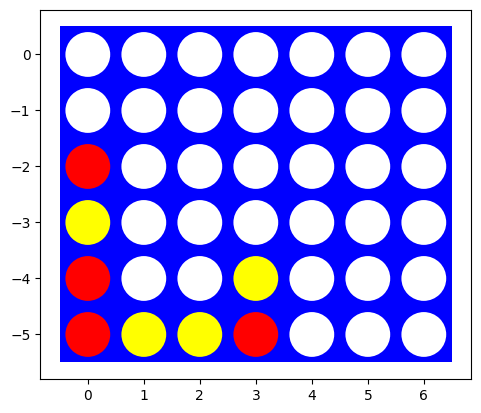

B6 bàn rỗng (6x7):


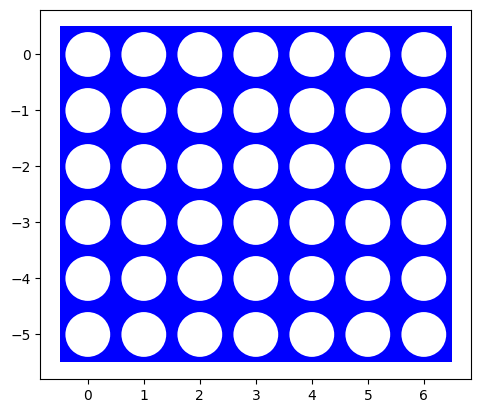

In [22]:
DEBUG = 0

def run_heuristic(board, player, cutoff):
    start = time.perf_counter()
    res = heuristic_alpha_beta_search(board, player = player, cutoff = cutoff)
    return res, COUNT, time.perf_counter() - start

print(f"{'Bàn 6x7':<24} | {'mong đợi':>8} | " + " | ".join(f"{'cutoff=' + str(c):>24}" for c in [2, 4, 6]))
print(f"{'':<24} | {'':>8} | " + " | ".join(f"{'nước  giá trị    nút    s':>24}" for c in [2, 4, 6]))
for name, (pattern, expected) in TEST_BOARDS.items():
    board = make_board(pattern, (6, 7))
    row = []
    for cutoff in [2, 4, 6]:
        res, nodes, t = run_heuristic(board, 1, cutoff)
        row.append(f"{res['move']:>4} {res['value']:>8.3f} {nodes:>6,} {t:>5.2f}")
    expected = "-" if name.startswith("B5") else expected   # thế ép chỉ đúng trên bàn 4x4 (xem nhận xét)
    print(f"{name:<24} | {str(expected):>8} | " + " | ".join(f"{r:>24}" for r in row))

for name in ["B5 thế ép (zugzwang)", "B6 bàn rỗng"]:
    print(name, "(6x7):")
    visualize(make_board(TEST_BOARDS[name][0], (6, 7)))

**Nhận xét:** * Trên bàn 6×7, **mọi cutoff (2, 4, 6) đều thấy nước thắng ngay** ở B1, B2 (giá trị 1,000 chỉ sau 14 nút với cutoff 2) **và nước chặn** ở B3, B4.
* **Bàn rỗng (B6):** cả 3 cutoff đều chọn **cột 3 (giữa)**. Đây đúng là nước đi tốt nhất đã biết của Connect 4, nhờ đặc trưng "quân ở cột giữa".
* **B5:** thế ép chỉ có trên bàn 4×4. Trên bàn 6×7 còn nhiều ô trống nên không còn nước nào chắc thắng (giá trị đều âm nhẹ).
  Cutoff 2 chọn cột 2, cutoff 4 và 6 chọn cột 3. Không có đáp án "đúng" để so.
* Chi phí rất nhỏ so với tìm kiếm đầy đủ: nhiều nhất 1.586 nút (0,13 giây) với cutoff 6.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [23]:
DEBUG = 0
print("Thời gian chọn nước đi đầu tiên (bàn rỗng) và nước giữa ván (bàn còn một nửa ô trống, TB 5 bàn):\n")
print(f"{'Bàn':>5} | {'cutoff':>6} | {'rỗng: nút':>10} {'s':>7} | {'giữa ván: nút TB':>16} {'s TB':>7}")
for shape in [(4, 4), (4, 5), (4, 6), (4, 7), (5, 7), (6, 7)]:
    mids = [random_board(shape, shape[0] * shape[1] // 2) for i in range(5)]
    for cutoff in [2, 4, 6]:
        res, n0, t0 = run_heuristic(empty_board(shape), 1, cutoff)
        stats = [run_heuristic(b, p, cutoff)[1:] for b, p in mids]
        print(f"{shape[0]}x{shape[1]:<3} | {cutoff:>6} | {n0:>10,} {t0:>7.3f} | "
              f"{np.mean([s[0] for s in stats]):>16,.0f} {np.mean([s[1] for s in stats]):>7.3f}")

Thời gian chọn nước đi đầu tiên (bàn rỗng) và nước giữa ván (bàn còn một nửa ô trống, TB 5 bàn):

  Bàn | cutoff |  rỗng: nút       s | giữa ván: nút TB    s TB
4x4   |      2 |         15   0.001 |               12   0.001
4x4   |      4 |        117   0.007 |               47   0.003


4x4   |      6 |        802   0.050 |              127   0.007
4x5   |      2 |         15   0.001 |               14   0.001
4x5   |      4 |         95   0.007 |               81   0.005


4x5   |      6 |        501   0.039 |              290   0.018
4x6   |      2 |         23   0.002 |               20   0.001


4x6   |      4 |        234   0.016 |              119   0.008

4x6   |      6 |      1,772   0.127 |              434   0.028
4x7   |      2 |         21   0.002 |               16   0.001
4x7   |      4 |        177   0.016 |              137   0.010


4x7   |      6 |      1,308   0.116 |              617   0.043
5x7   |      2 |         21   0.002 |               15   0.001
5x7   |      4 |        175   0.016 |               68   0.006


5x7   |      6 |      1,329   0.118 |              296   0.025
6x7   |      2 |         21   0.002 |               21   0.002
6x7   |      4 |        175   0.016 |              167   0.014


6x7   |      6 |      1,283   0.125 |              716   0.058


**Nhận xét:** * **Độ sâu cắt quyết định thời gian.** Trên bàn 6×7 rỗng, số nút tăng 21 → 175 → 1.283 (0,002 → 0,016 → 0,125 giây) khi cutoff tăng 2 → 4 → 6, tức khoảng 7–8 lần cho mỗi 2 nước thêm.
* **Kích thước bàn ảnh hưởng ít hơn**, vì độ sâu đã bị giới hạn. Chỉ số cột (hệ số rẽ nhánh) mới có tác động.
  Ví dụ với cutoff 6, bàn 4×4 cần 802 nút, các bàn 7 cột cần khoảng 1.300 nút. Thêm hàng (4×7 → 5×7 → 6×7) gần như không đổi số nút ở bàn rỗng.
* **Giữa ván rẻ hơn đầu ván** (ví dụ 6×7 cutoff 6: 716 nút so với 1.283), vì có cột đã đầy và có nhiều nước quyết định để cắt tỉa.
* Mọi cấu hình đều dưới 0,13 giây/nước, nên trên bàn chuẩn có thể dùng cutoff 6, thậm chí sâu hơn.

### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

heuristic cutoff 2 (Đỏ) vs. heuristic cutoff 4 (Vàng):


{1: 0, -1: 0, 'd': 1}

CPU times: user 209 ms, sys: 637 μs, total: 210 ms
Wall time: 210 ms
heuristic cutoff 4 (Đỏ) vs. heuristic cutoff 2 (Vàng):


{1: 1, -1: 0, 'd': 0}

CPU times: user 116 ms, sys: 777 μs, total: 116 ms
Wall time: 116 ms
heuristic cutoff 2 (Đỏ) vs. heuristic cutoff 6 (Vàng):


{1: 1, -1: 0, 'd': 0}

CPU times: user 1.45 s, sys: 2.05 ms, total: 1.45 s
Wall time: 1.45 s
heuristic cutoff 6 (Đỏ) vs. heuristic cutoff 2 (Vàng):


{1: 1, -1: 0, 'd': 0}

CPU times: user 924 ms, sys: 1.77 ms, total: 926 ms
Wall time: 925 ms
heuristic cutoff 4 (Đỏ) vs. heuristic cutoff 6 (Vàng):


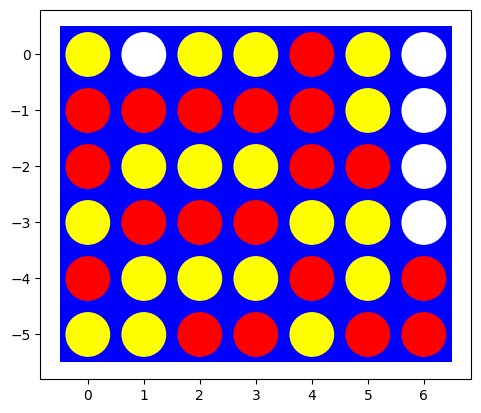

{1: 1, -1: 0, 'd': 0}

CPU times: user 1.69 s, sys: 4.64 ms, total: 1.69 s
Wall time: 1.69 s
heuristic cutoff 6 (Đỏ) vs. heuristic cutoff 4 (Vàng):


{1: 0, -1: 0, 'd': 1}

CPU times: user 963 ms, sys: 1.82 ms, total: 965 ms
Wall time: 964 ms


In [24]:
DEBUG = 0
h2 = SearchAgent(heuristic_alpha_beta_search, name = "heuristic cutoff 2", cutoff = 2)
h4 = SearchAgent(heuristic_alpha_beta_search, name = "heuristic cutoff 4", cutoff = 4)
h6 = SearchAgent(heuristic_alpha_beta_search, name = "heuristic cutoff 6", cutoff = 6)

# Không có yếu tố ngẫu nhiên -> mỗi cặp chỉ cần đấu 1 ván cho mỗi bên đi trước (1 = Đỏ thắng, -1 = Vàng thắng)
for a, b in [(h2, h4), (h4, h2), (h2, h6), (h6, h2), (h4, h6), (h6, h4)]:
    print(f"{a.name} (Đỏ) vs. {b.name} (Vàng):")
    %time display(play(a.act, b.act, N = 1, show_final_board = (a is h4 and b is h6)))

**Nhận xét:** Kết quả 6 ván (mỗi cặp đổi lượt đi trước):

| Đỏ (đi trước) | Vàng | Kết quả |
|---|---|---|
| cutoff 2 | cutoff 4 | hòa |
| cutoff 4 | cutoff 2 | Đỏ (cutoff 4) thắng |
| cutoff 2 | cutoff 6 | Đỏ (cutoff 2) thắng |
| cutoff 6 | cutoff 2 | Đỏ (cutoff 6) thắng |
| cutoff 4 | cutoff 6 | Đỏ (cutoff 4) thắng |
| cutoff 6 | cutoff 4 | hòa |

* **Người đi trước thắng 4/6 ván, 2 ván hòa, người đi sau chưa thắng ván nào.** Lợi thế đi trước rất rõ.
* **Tìm sâu hơn không chắc thắng.** Cutoff 2 đi trước thắng cả cutoff 6, cutoff 4 đi trước thắng cutoff 6.
  Lý do: hàm đánh giá còn thô (không biết ai đi tiếp, không biết các đe dọa ở hàng chẵn/lẻ quan trọng ở cuối ván), nên nhìn sâu hơn với một hàm đánh giá sai không giúp được nhiều.
  Ngoài ra mỗi cặp chỉ có 1 ván (agent tất định), nên đây là mẫu rất nhỏ.
* Đổi lại, agent sâu hơn tốn thời gian hơn: khoảng 1–1,7 giây mỗi ván cho cặp có cutoff 6, so với 0,1–0,2 giây cho cutoff 2 với 4.

In [25]:
# Heuristic agent đấu random trên bàn 6x7 (dùng cho bảng tổng hợp cuối notebook)
DEBUG = 0
for agent in [h2, h4]:
    for first in [True, False]:
        agent.reset_stats()
        start = time.perf_counter()
        res = play(agent.act, random_player) if first else play(random_player, agent.act)
        me = 1 if first else -1
        SUMMARY[(agent.name, "đi trước" if first else "đi sau")] = (100, res[me], res['d'], res[-me], agent.avg_time())
        print(f"{agent.name} {'(Đỏ)' if first else '(Vàng)'} vs. random: {res}, "
              f"TB {agent.avg_time() * 1000:.1f} ms/nước, tổng {time.perf_counter() - start:.1f} s")

heuristic cutoff 2 (Đỏ) vs. random: {1: 100, -1: 0, 'd': 0}, TB 0.9 ms/nước, tổng 0.6 s
heuristic cutoff 2 (Vàng) vs. random: {1: 0, -1: 100, 'd': 0}, TB 1.2 ms/nước, tổng 0.9 s


heuristic cutoff 4 (Đỏ) vs. random: {1: 100, -1: 0, 'd': 0}, TB 7.2 ms/nước, tổng 3.7 s


heuristic cutoff 4 (Vàng) vs. random: {1: 0, -1: 100, 'd': 0}, TB 12.7 ms/nước, tổng 8.1 s


**Nhận xét:** * Cả cutoff 2 và cutoff 4 đều **thắng 100/100 ván** trước Random, dù đi trước hay đi sau.
* Thời gian trung bình: cutoff 2 khoảng **0,9–1,2 ms/nước**, cutoff 4 khoảng **7–13 ms/nước**. Đi sau tốn hơn một chút vì phải xử lý nhiều đe dọa hơn.
* Random quá yếu nên không phân biệt được hai độ sâu. Muốn so sánh độ sâu cắt thì phải cho các agent đấu nhau (ô trên).

## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [26]:
def playout(board, action, player = 1):
    """Chơi ngẫu nhiên tới hết ván, bắt đầu bằng action của player. Trả về utility của ván (góc nhìn player)."""
    board = result(board, player, action)
    current_player = -player

    while True:
        # reached terminal state?
        u = utility(board, player)
        if u is not None: return u

        # we use a random playout policy
        a = np.random.choice(actions(board))
        board = result(board, current_player, a)

        # switch between players
        current_player = -current_player

def playouts(board, action, player = 1, N = 100):
    """Perform N playouts following the given action for the given board."""
    return [playout(board, action, player) for i in range(N)]

DEBUG = 1

def pmcs(board, N = 100, player = 1):
    """Pure Monte Carlo Search. Trả về nước đi có utility trung bình lớn nhất.
    N playout được chia đều cho các nước đi hợp lệ (ít nhất 1 playout mỗi nước)."""
    global DEBUG

    acts = actions(board)
    n = max(math.floor(N / len(acts)), 1)
    if DEBUG >= 1: print(f"Actions: {acts} ({N} total playouts = {n} playouts per action)")

    ps = {i: np.mean(playouts(board, i, player, N = n)) for i in acts}
    if DEBUG >= 1: display({a: round(float(v), 3) for a, v in ps.items()})

    action = max(ps, key = ps.get)
    return action

board = empty_board()
%time print("Nước đi:", pmcs(board, N = 700))

Actions: [0, 1, 2, 3, 4, 5, 6] (700 total playouts = 100 playouts per action)


{0: 0.06, 1: -0.12, 2: 0.14, 3: 0.3, 4: 0.22, 5: 0.04, 6: -0.04}

Nước đi: 3
CPU times: user 247 ms, sys: 29.3 ms, total: 276 ms
Wall time: 246 ms


Cài đặt giống `tictactoe_pure_monte_carlo_search.ipynb`. Chỉ khác là đối thủ của `player` là `-player`, và mỗi nước có ít nhất 1 playout
(với N = 10 và 7 cột, `floor(10/7) = 1`).

Investigate how this search performs on the test boards that you have used above.

In [27]:
DEBUG = 0
print("PMCS trên các bàn kiểm thử 6x7. Mỗi cấu hình chạy 5 lần để xem nước đi có ổn định không:\n")
print(f"{'Bàn 6x7':<24} | {'mong đợi':>8} | {'N':>5} | {'nước đi qua 5 lần':>18} | {'s/lần':>6}")
for name, (pattern, expected) in TEST_BOARDS.items():
    board = make_board(pattern, (6, 7))
    for N in [10, 100, 1000]:
        start = time.perf_counter()
        moves = [pmcs(board, N = N, player = 1) for i in range(5)]
        t = (time.perf_counter() - start) / 5
        print(f"{name:<24} | {str(expected):>8} | {N:>5} | {str(moves):>18} | {t:>6.3f}")

PMCS trên các bàn kiểm thử 6x7. Mỗi cấu hình chạy 5 lần để xem nước đi có ổn định không:

Bàn 6x7                  | mong đợi |     N |  nước đi qua 5 lần |  s/lần
B1 thắng ngay (ngang)    |        3 |    10 |    [0, 1, 3, 2, 0] |  0.002
B1 thắng ngay (ngang)    |        3 |   100 |    [3, 3, 3, 3, 3] |  0.016


B1 thắng ngay (ngang)    |        3 |  1000 |    [3, 3, 3, 3, 3] |  0.160
B2 thắng ngay (dọc)      |        0 |    10 |    [0, 0, 0, 0, 0] |  0.001
B2 thắng ngay (dọc)      |        0 |   100 |    [0, 0, 0, 0, 0] |  0.016


B2 thắng ngay (dọc)      |        0 |  1000 |    [0, 0, 0, 0, 0] |  0.160
B3 phải chặn (dọc)       |        0 |    10 |    [3, 0, 2, 0, 0] |  0.001
B3 phải chặn (dọc)       |        0 |   100 |    [0, 1, 4, 0, 0] |  0.017


B3 phải chặn (dọc)       |        0 |  1000 |    [0, 0, 0, 0, 0] |  0.170
B4 phải chặn (ngang)     |        3 |    10 |    [0, 1, 0, 3, 3] |  0.001
B4 phải chặn (ngang)     |        3 |   100 |    [3, 3, 3, 3, 3] |  0.016


B4 phải chặn (ngang)     |        3 |  1000 |    [3, 3, 3, 3, 3] |  0.178
B5 thế ép (zugzwang)     |        2 |    10 |    [0, 0, 1, 1, 1] |  0.002
B5 thế ép (zugzwang)     |        2 |   100 |    [3, 2, 2, 2, 1] |  0.022


B5 thế ép (zugzwang)     |        2 |  1000 |    [2, 2, 2, 2, 2] |  0.229
B6 bàn rỗng              |     None |    10 |    [0, 1, 0, 0, 0] |  0.003
B6 bàn rỗng              |     None |   100 |    [3, 1, 4, 5, 3] |  0.031


B6 bàn rỗng              |     None |  1000 |    [3, 3, 4, 3, 3] |  0.315


**Nhận xét:** * **N = 10 không ổn định:** mỗi nước chỉ có 1 playout. Ví dụ B1 cho các nước [0, 1, 3, 2, 0], chỉ 1/5 lần đúng.
* **N = 100** đã ổn định với nước thắng ngay và nước chặn ngang (B1, B2, B4 đúng 5/5), nhưng B3 và B5 mới đúng 3/5.
* **N = 1000** cho kết quả **ổn định ở mọi bàn B1–B5** (5/5 lần như nhau). Ở bàn rỗng, 4/5 lần chọn cột giữa (3).
  PMCS với N = 1000 luôn chọn cột 2 ở B5 trên bàn 6×7. Theo playout ngẫu nhiên thì đó là nước có tỷ lệ thắng cao nhất,
  nhưng không có nghĩa là nước chắc thắng (khác với bàn 4×4).
* Thời gian tăng tuyến tính theo N: khoảng 0,002 → 0,016 → 0,16–0,32 giây cho N = 10 → 100 → 1000.

In [28]:
DEBUG = 0
p100 = SearchAgent(pmcs, name = "PMCS N=100", use_memory = False, N = 100)
p1000 = SearchAgent(pmcs, name = "PMCS N=1000", use_memory = False, N = 1000)

for agent, n_games in [(p100, 100), (p1000, 20)]:
    for first in [True, False]:
        agent.reset_stats()
        start = time.perf_counter()
        res = play(agent.act, random_player, N = n_games) if first else play(random_player, agent.act, N = n_games)
        me = 1 if first else -1
        SUMMARY[(agent.name, "đi trước" if first else "đi sau")] = (n_games, res[me], res['d'], res[-me], agent.avg_time())
        print(f"{agent.name} {'(Đỏ)' if first else '(Vàng)'} vs. random ({n_games} ván): {res}, "
              f"TB {agent.avg_time() * 1000:.1f} ms/nước, tổng {time.perf_counter() - start:.1f} s")

PMCS N=100 (Đỏ) vs. random (100 ván): {1: 99, -1: 1, 'd': 0}, TB 22.9 ms/nước, tổng 14.6 s


PMCS N=100 (Vàng) vs. random (100 ván): {1: 1, -1: 99, 'd': 0}, TB 21.5 ms/nước, tổng 16.0 s


PMCS N=1000 (Đỏ) vs. random (20 ván): {1: 20, -1: 0, 'd': 0}, TB 243.4 ms/nước, tổng 28.2 s


PMCS N=1000 (Vàng) vs. random (20 ván): {1: 0, -1: 20, 'd': 0}, TB 244.4 ms/nước, tổng 29.8 s


**Nhận xét:** * PMCS N = 100 thắng Random **99/100** ván, cả khi đi trước lẫn đi sau, mất khoảng **22 ms/nước**.
* PMCS N = 1000 thắng **20/20** ván ở cả hai lượt, nhưng mất khoảng **244 ms/nước**, gấp khoảng 10 lần.
* PMCS không cần kiến thức gì về Connect 4: chỉ cần luật chơi và mô phỏng ngẫu nhiên là đủ để thắng Random gần như tuyệt đối.

In [29]:
# PMCS đấu heuristic alpha-beta trên bàn 6x7. PMCS có yếu tố ngẫu nhiên nên đấu nhiều ván mỗi bên đi trước.
DEBUG = 0
for pm, n_games in [(p100, 10), (p1000, 5)]:
    for h in [h2, h4]:
        pm.reset_stats(); h.reset_stats()
        r1 = play(pm.act, h.act, N = n_games)
        r2 = play(h.act, pm.act, N = n_games)
        print(f"{pm.name} vs. {h.name}: PMCS đi trước {r1} | {h.name} đi trước {r2} | "
              f"TB/nước: PMCS {pm.avg_time() * 1000:.0f} ms, heuristic {h.avg_time() * 1000:.0f} ms")

PMCS N=100 vs. heuristic cutoff 2: PMCS đi trước {1: 0, -1: 10, 'd': 0} | heuristic cutoff 2 đi trước {1: 10, -1: 0, 'd': 0} | TB/nước: PMCS 23 ms, heuristic 1 ms


PMCS N=100 vs. heuristic cutoff 4: PMCS đi trước {1: 0, -1: 10, 'd': 0} | heuristic cutoff 4 đi trước {1: 9, -1: 1, 'd': 0} | TB/nước: PMCS 22 ms, heuristic 11 ms


PMCS N=1000 vs. heuristic cutoff 2: PMCS đi trước {1: 1, -1: 4, 'd': 0} | heuristic cutoff 2 đi trước {1: 4, -1: 1, 'd': 0} | TB/nước: PMCS 209 ms, heuristic 1 ms


PMCS N=1000 vs. heuristic cutoff 4: PMCS đi trước {1: 0, -1: 5, 'd': 0} | heuristic cutoff 4 đi trước {1: 3, -1: 2, 'd': 0} | TB/nước: PMCS 186 ms, heuristic 9 ms


Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

**Heuristic Alpha-Beta mạnh hơn PMCS** trên bàn 6×7 trong các thí nghiệm này:

| Trận (đổi lượt đi trước) | PMCS thắng | Heuristic thắng | TG TB/nước PMCS | TG TB/nước heuristic |
|---|---|---|---|---|
| PMCS N=100 vs. cutoff 2 (20 ván) | 0 | 20 | 23 ms | 1 ms |
| PMCS N=100 vs. cutoff 4 (20 ván) | 1 | 19 | 22 ms | 11 ms |
| PMCS N=1000 vs. cutoff 2 (10 ván) | 2 | 8 | 209 ms | 1 ms |
| PMCS N=1000 vs. cutoff 4 (10 ván) | 2 | 8 | 186 ms | 9 ms |

Vì sao:

* **Mô hình đối thủ:** playout ngẫu nhiên ước lượng giá trị nước đi khi *cả hai bên chơi ngẫu nhiên*.
  Một nước để đối thủ thắng ngay ở nước sau vẫn có thể có điểm trung bình cao, vì Random thường bỏ lỡ nước thắng đó.
  Alpha-Beta giả định đối thủ chọn nước tốt nhất cho họ, nên không mắc lỗi này.
* **Kiến thức về trò chơi:** hàm đánh giá chứa sẵn hiểu biết (đoạn 3 quân, cột giữa), còn PMCS phải tự "học" từ mô phỏng.
* **Hiệu quả thời gian:** heuristic cutoff 2 chỉ mất khoảng 1 ms/nước mà vẫn thắng PMCS N = 1000 (khoảng 200 ms/nước).

Sức mạnh của mỗi cách phụ thuộc vào:

* **PMCS:** số playout N (N = 1000 thắng 4/20 ván, N = 100 chỉ thắng 1/40) và chất lượng chính sách playout. Playout thông minh hơn ngẫu nhiên, hoặc MCTS/UCT xây cây sâu hơn, sẽ mạnh hơn nhiều.
* **Heuristic Alpha-Beta:** chất lượng hàm đánh giá và độ sâu cắt.

PMCS có ưu điểm là không cần thiết kế hàm đánh giá, và dễ áp dụng cho trò chơi mới.

## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning 

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth. 
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards. 

Show the tradeoff in an appropriate graph.  

*Phần này không bắt buộc với sinh viên đại học; nhóm không làm.*

#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above. 

*Không làm (phần không bắt buộc).*

### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

*Không làm (phần không bắt buộc).*

## Tổng hợp kết quả Connect 4

Bảng dưới lấy số từ các thí nghiệm ở trên (Alpha-Beta đầy đủ chỉ chạy được trên bàn 4×4; các agent còn lại chơi bàn chuẩn 6×7).

In [30]:
print(f"{'Tác tử':<20} | {'Đối thủ':<7} | {'Lượt':<8} | {'Số ván':>6} | {'Thắng':>5} | {'Hòa':>4} | {'Thua':>4} | {'TG TB/nước':>10}")
for (name, turn), (n, w, d, l, t) in SUMMARY.items():
    t = "-" if t is None else f"{t * 1000:.1f} ms"
    print(f"{name:<20} | {'Random':<7} | {turn:<8} | {n:>6} | {w:>5} | {d:>4} | {l:>4} | {t:>10}")

Tác tử               | Đối thủ | Lượt     | Số ván | Thắng |  Hòa | Thua | TG TB/nước
Random (6x7)         | Random  | đi trước |   1000 |   541 |    2 |  457 |          -
Alpha-Beta (4x4)     | Random  | đi trước |    100 |    52 |   48 |    0 |    10.5 ms
Alpha-Beta (4x4)     | Random  | đi sau   |    100 |    79 |   21 |    0 |    14.6 ms
heuristic cutoff 2   | Random  | đi trước |    100 |   100 |    0 |    0 |     0.9 ms
heuristic cutoff 2   | Random  | đi sau   |    100 |   100 |    0 |    0 |     1.2 ms
heuristic cutoff 4   | Random  | đi trước |    100 |   100 |    0 |    0 |     7.2 ms
heuristic cutoff 4   | Random  | đi sau   |    100 |   100 |    0 |    0 |    12.7 ms
PMCS N=100           | Random  | đi trước |    100 |    99 |    0 |    1 |    22.9 ms
PMCS N=100           | Random  | đi sau   |    100 |    99 |    0 |    1 |    21.5 ms
PMCS N=1000          | Random  | đi trước |     20 |    20 |    0 |    0 |   243.4 ms
PMCS N=1000          | Random  | đi sau   |     20 |  

**Nhận xét tổng hợp:**

1. **Chất lượng nước đi:** mọi agent tìm kiếm đều áp đảo Random. Alpha-Beta đầy đủ không thua ván nào trên bàn 4×4. Heuristic cutoff 2 và 4 thắng 100% trên bàn 6×7. PMCS thắng 99–100%.
   Khi các agent đấu nhau, heuristic Alpha-Beta mạnh hơn PMCS rõ rệt.
2. **Số nút và khả năng mở rộng:** tìm kiếm đầy đủ tăng theo hàm mũ. Mỗi ô trống thêm vào nhân số nút lên khoảng 2,6 lần, và bàn 4×5 đã cần 18 triệu nút.
   Heuristic với cutoff 6 trên bàn 6×7 chỉ cần nhiều nhất khoảng 1.600 nút.
3. **Thời gian:**
   * Heuristic: 1–13 ms/nước.
   * PMCS: 22 ms/nước (N = 100) và 244 ms/nước (N = 1000).
   * Alpha-Beta trên bàn 4×4: 10–15 ms/nước. Con số này chỉ đạt được nhờ memory, vì riêng nước đầu đã mất 0,56 giây.
4. **Move ordering** (thắng trước, chặn sau) giảm tổng số nút khoảng 2,2 lần, nhiều nhất ở các bàn đã có nước quyết định.
5. **Lợi thế đi trước:** Random đi trước thắng 54,1% so với 45,7%. Khi các heuristic agent đấu nhau, người đi sau không thắng ván nào.